### Section 4: Measures of Shape & Distribution Geometry
#### Skewness, Kurtosis, Statistical Moments & Distribution Geometry

While **central tendency** gives the middle (1st moment) and **dispersion** measures the spread (2nd moment), **measures of shape** describe the geometry and asymmetry of the distribution:
> **"Is the distribution lopsided (Skewness)? Are extreme outlier tails heavy or light (Kurtosis)?"**

Below are clear, naive examples covering the core measures of shape and distribution geometry, complete with mathematical formulas, notation pronunciations, and Python implementation comparisons across **Plain Python**, **Standard Library `statistics`**, **`NumPy`**, **`SciPy`**, **`Matplotlib`**, and **`Seaborn`**:
1. **The Four Statistical Moments**
2. **Skewness (Asymmetry of the Distribution)**
3. **Kurtosis & Excess Kurtosis (Tail Thickness & Extremity)**
4. **Deep-Dive: The 3 Types of Kurtosis (Mesokurtic, Leptokurtic, Platykurtic) with Everyday Examples**
5. **Pearson's Median Skewness Coefficient (Robust Non-Parametric Skew)**
6. **Fixing Skewness (Log & Power Transformations)**
7. **Master Summary Cheat Sheet & Decision Matrix**
---
---


### Setup


In [2]:
import math
import statistics
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot style
plt.style.use('seaborn_v0_8_white' if 'seaborn_v0_8_white' in plt.style.available else 'default')
plt.rcParams["figure.dpi"] = 100
np.random.seed(42)

print("Libraries imported successfully!")


Libraries imported successfully!


---
## 1. The Four Statistical Moments of a Distribution

Every distribution's geometry can be mathematically described by **four fundamental moments**:

| Moment | Name | Mathematical Formula | What it Describes |
| :---: | :---: | :---: | :--- |
| **1st Moment** | **Mean ($\mu$)** | $\frac{1}{n}\sum x_i$ | **Location / Center:** Center of mass of data |
| **2nd Moment** | **Variance ($\sigma^2$)** | $\frac{1}{n}\sum (x_i - \mu)^2$ | **Scale / Dispersion:** Spread around the center |
| **3rd Moment** | **Skewness ($g_1$)** | $\frac{1}{n\sigma^3}\sum (x_i - \mu)^3$ | **Asymmetry / Shape:** Left vs. Right tail stretch |
| **4th Moment** | **Kurtosis ($a_4$)** | $\frac{1}{n\sigma^4}\sum (x_i - \mu)^4$ | **Tails / Extremes:** Propensity for extreme outlier events |


--- 
## 2. Skewness (Asymmetry of the Distribution)

* **What it does:** Measures the degree and direction of asymmetry in a distribution relative to a symmetrical normal distribution.
* **Three Shapes:**
  * **Positive Skew ($> 0$):** Long tail on the **right**; $\text{Mean} > \text{Median} > \text{Mode}$.
  * **Symmetric ($= 0$):** Equal balance; $\text{Mean} = \text{Median} = \text{Mode}$.
  * **Negative Skew ($< 0$):** Long tail on the **left**; $\text{Mean} < \text{Median} < \text{Mode}$.
* **Mathematical Notation:**
  $$\text{Skewness} = \frac{\frac{1}{n} \sum_{i=1}^{n} (x_i - \bar{x})^3}{s^3} = \frac{m_3}{s^3}$$
  *Where:*
  * $m_3$ (*m three*): 3rd central moment (cubed deviations from mean)
  * $s^3$ (*s cubed*): Standard deviation raised to 3rd power
* **Naive Example:** Department salaries in thousands: `[30, 35, 40, 45, 250]` ($n = 5$). The executive salary (250) pulls the tail right.
  $$\text{Skewness} \approx +1.48 \quad (\text{Right-Skewed / Positively Skewed})$$
* **When to use:** Detecting distribution distortion, checking normality for linear regression / ANOVA, and identifying income or price disparity.


Salaries Dataset: [30, 35, 40, 45, 250]
Mean: 80.0k, Median: 40.0k
-------------------------------------------------------
Plain Python (Population Skewness): +1.487
SciPy Population Skew (bias=True):  +1.487
SciPy Sample Skew (bias=False):      +2.217


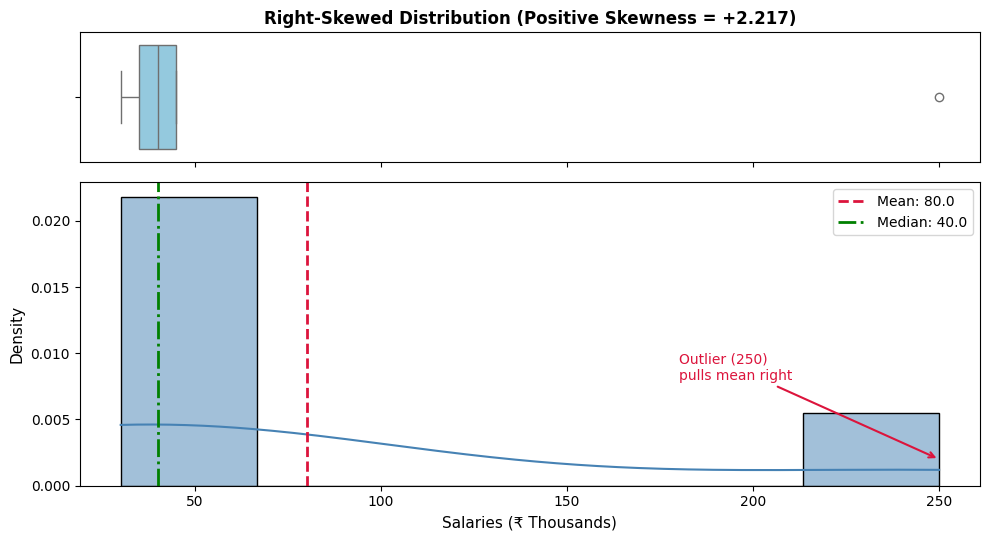

In [5]:
# 1. Skewness Example
salaries = [30, 35, 40, 45, 250]
n = len(salaries)

# Plain Python
median_val = np.median(salaries)
mean_val = sum(salaries) / n
var_val = sum((x - mean_val) ** 2 for x in salaries) / n
std_val = math.sqrt(var_val)
m3 = sum((x - mean_val) ** 3 for x in salaries) / n
skew_python = m3 / (std_val ** 3)

# SciPy Library
# bias=True calculates population skewness; bias=False applies sample correction
skew_scipy_pop = stats.skew(salaries, bias=True)
skew_scipy_sample = stats.skew(salaries, bias=False)

print(f"Salaries Dataset: {salaries}")
print(f"Mean: {mean_val:.1f}k, Median: {median_val:.1f}k")
print("-" * 55)
print(f"Plain Python (Population Skewness): {skew_python:+.3f}")
print(f"SciPy Population Skew (bias=True):  {skew_scipy_pop:+.3f}")
print(f"SciPy Sample Skew (bias=False):      {skew_scipy_sample:+.3f}")

# Visualization Setup: Boxplot + Histogram with KDE
fig, (ax_box, ax_hist) = plt.subplots(
    2, 1, figsize=(10, 5.5), sharex=True, gridspec_kw={"height_ratios": [0.3, 0.7]}
)

# 1. Top Panel: Boxplot
sns.boxplot(x=salaries, ax=ax_box, color="skyblue", fliersize=6, orient="h")
ax_box.set(xlabel="")
ax_box.set_title(
    f"Right-Skewed Distribution (Positive Skewness = {skew_scipy_sample:+.3f})",
    fontsize=12,
    fontweight="bold",
)

# 2. Bottom Panel: Histogram and KDE
sns.histplot(salaries, kde=True, ax=ax_hist, color="steelblue", bins=6, stat="density")

# Annotate Mean vs Median to show the effect of the outlier on skewness
ax_hist.axvline(mean_val, color="crimson", linestyle="--", linewidth=2, label=f"Mean: {mean_val:.1f}")
ax_hist.axvline(median_val, color="green", linestyle="-.", linewidth=2, label=f"Median: {median_val:.1f}")

# Annotate Outlier Point
ax_hist.annotate(
    "Outlier (250)\npulls mean right",
    xy=(250, 0.002),
    xytext=(180, 0.008),
    arrowprops=dict(arrowstyle="->", color="crimson", lw=1.5),
    fontsize=10,
    color="crimson",
)

ax_hist.set_xlabel("Salaries (₹ Thousands)", fontsize=11)
ax_hist.set_ylabel("Density", fontsize=11)
ax_hist.legend(loc="upper right", frameon=True)

plt.tight_layout()
plt.show()


---
## 3. Kurtosis & Excess Kurtosis (Tail Thickness & Extremity)

* **What it does:** Measures tail weight and the likelihood of extreme outliers compared to a normal distribution.
  * **Leptokurtic (Excess Kurtosis $> 0$):** Heavy tails, high outlier risk (e.g., financial markets).
  * **Mesokurtic (Excess Kurtosis $\approx 0$):** Normal distribution tails (Gaussian bell curve).
  * **Platykurtic (Excess Kurtosis $< 0$):** Thin tails, uniform spread, rare outliers.
* **Mathematical Notation:**
  $$\text{Kurtosis} = \frac{\frac{1}{n} \sum_{i=1}^{n} (x_i - \bar{x})^4}{s^4} = \frac{m_4}{s^4}$$
  $$\text{Excess Kurtosis} = \text{Kurtosis} - 3$$
  *Where:*
  * $m_4$ (*m four*): 4th central moment (fourth-power deviations)
  * $s^4$ (*s to the 4th*): Standard deviation raised to 4th power
  * $-3$ (*minus three*): Baseline subtraction so normal distribution equals 0
* **Naive Example:** Stock daily returns in percentage: `[-10, -0.5, 0, 0.5, 12]` ($n = 5$). Presence of extreme +/-10% days creates heavy tails.
  $$\text{Excess Kurtosis} \approx +0.12 \quad (\text{Leptokurtic / Heavy-Tailed})$$
* **When to use:** Financial risk management (Value at Risk), quality control anomaly detection, and robust statistical testing.


Returns Dataset: [-10, -0.5, 0, 0.5, 12]
Plain Python (Excess Kurtosis):      -0.491
SciPy Excess Kurtosis (fisher=True): -0.491
SciPy Raw Kurtosis (fisher=False):   +2.509


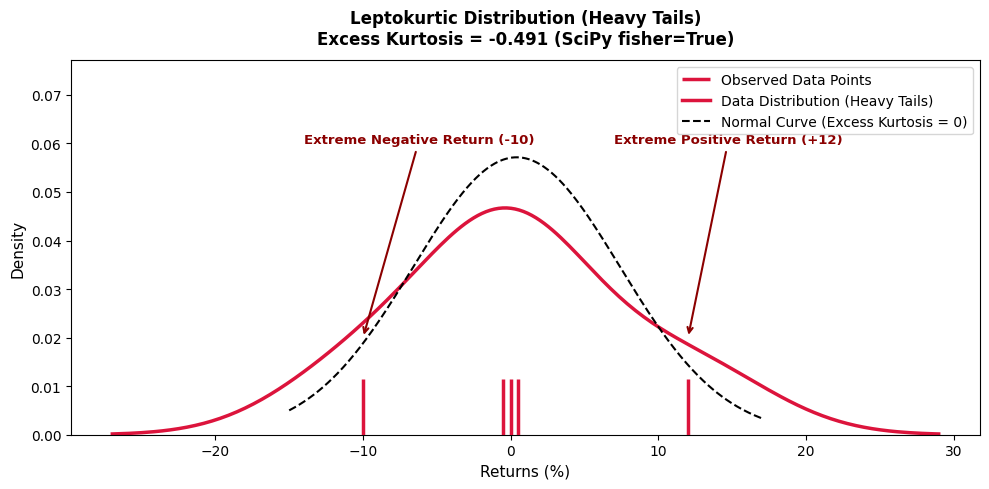

In [7]:
# 2. Excess Kurtosis Example
returns = [-10, -0.5, 0, 0.5, 12]
n = len(returns)

# Plain Python
mean_val = sum(returns) / n
var_val = sum((x - mean_val) ** 2 for x in returns) / n
std_val = math.sqrt(var_val)
m4 = sum((x - mean_val) ** 4 for x in returns) / n
kurtosis_raw = m4 / (std_val ** 4)
excess_kurtosis_python = kurtosis_raw - 3.0

# SciPy Library (fisher=True calculates Excess Kurtosis relative to 3.0)
excess_kurt_scipy = stats.kurtosis(returns, fisher=True, bias=True)
raw_kurt_scipy = stats.kurtosis(returns, fisher=False, bias=True)

print(f"Returns Dataset: {returns}")
print(f"Plain Python (Excess Kurtosis):      {excess_kurtosis_python:+.3f}")
print(f"SciPy Excess Kurtosis (fisher=True): {excess_kurt_scipy:+.3f}")
print(f"SciPy Raw Kurtosis (fisher=False):   {raw_kurt_scipy:+.3f}")

# Visualization Setup: Rugplot + KDE + Normal Curve Reference
fig, ax = plt.subplots(figsize=(10, 5))

# Plot observed data markers and kernel density
sns.rugplot(returns, ax=ax, color="crimson", height=0.15, linewidth=2.5, label="Observed Data Points", zorder=5)
sns.kdeplot(returns, ax=ax, color="crimson", linewidth=2.5, label="Data Distribution (Heavy Tails)")

# Overlay reference Normal Distribution with same mean & std
x_range = np.linspace(min(returns) - 5, max(returns) + 5, 500)
norm_pdf = stats.norm.pdf(x_range, loc=mean_val, scale=std_val)
ax.plot(x_range, norm_pdf, "k--", linewidth=1.5, label="Normal Curve (Excess Kurtosis = 0)")

# Annotate Extreme Tail Outliers contributing to high m4
ax.annotate(
    "Extreme Negative Return (-10)",
    xy=(-10, 0.02),
    xytext=(-14, 0.06),
    arrowprops=dict(arrowstyle="->", color="darkred", lw=1.5),
    fontsize=9.5,
    color="darkred",
    fontweight="bold",
)

ax.annotate(
    "Extreme Positive Return (+12)",
    xy=(12, 0.02),
    xytext=(7, 0.06),
    arrowprops=dict(arrowstyle="->", color="darkred", lw=1.5),
    fontsize=9.5,
    color="darkred",
    fontweight="bold",
)

ax.set_title(
    f"Leptokurtic Distribution (Heavy Tails)\nExcess Kurtosis = {excess_kurt_scipy:+.3f} (SciPy fisher=True)",
    fontsize=12,
    pad=12,
    fontweight="bold"
)
ax.set_xlabel("Returns (%)", fontsize=11)
ax.set_ylabel("Density", fontsize=11)
ax.legend(loc="upper right", frameon=True)

plt.tight_layout()
plt.show()


---
## 4. Deep-Dive: The 3 Types of Kurtosis Explained with Everyday Examples

### What Kurtosis Truly Measures (Debunking the "Peakedness" Myth):
* **The Common Misconception:** Many beginner textbooks state kurtosis simply measures how "sharp" or "peaked" the center is.
* **The Modern Statistical Reality (Westfall, 2014):** Kurtosis primarily measures **tail-weight and outlier propensity**!
* In simple terms, Kurtosis answers:
  > *"How frequently do extreme, unexpected outlier events occur in this distribution compared to a normal bell curve?"*

---

### Comparison of the Three Types:

| Type | Greek Root | Excess Kurtosis ($\gamma_2$) | Tail Nature | Probability of Outliers | Real-World Everyday Examples |
| :--- | :--- | :---: | :--- | :---: | :--- |
| **1. Mesokurtic** | *Meso* = Middle | $\gamma_2 \approx 0$ (Full $\beta_2 \approx 3$) | **Moderate / Standard Tails** | **Low (Normal)**  <br>($|z| > 3$ occurs only 0.27% of the time) | • Adult human heights in a demographic<br>• Calibrated factory bottle-filling (500ml)<br>• Standardized IQ test scores ($\mu=100, \sigma=15$) |
| **2. Leptokurtic** | *Lepto* = Slender / Fat-tailed | $\mathbf{\gamma_2 > 0}$ (Full $\beta_2 > 3$) | **Heavy, Fat, Thick Tails** <br>*(sharp peak with fat tails)* | **Very High (Fat-Tailed Risk)** <br>Extreme "Black Swan" events occur often! | • **Financial & Crypto Returns:** Most days fluctuate near 0%, but occasional massive crashes (-15%) or surges (+40%) create fat tails.<br>• **Server API Latency:** 99% of requests take 15ms, but rare database locks cause 5,000ms spikes.<br>• **Earthquake Energy:** Frequent micro-tremors, but occasional massive destructive quakes. |
| **3. Platykurtic** | *Platy* = Broad / Flat-topped | $\mathbf{\gamma_2 < 0}$ (Full $\beta_2 < 3$) | **Thin, Light, Short Tails** <br>*(flat top / plateau)* | **Virtually Zero** <br>Values stay bounded; no extreme outliers | • **Rolling a Fair 6-Sided Die:** Equal probability for {1, 2, 3, 4, 5, 6}; no outliers beyond 1 or 6.<br>• **Laser-Inspected Manufacturing:** Parts deviating by >0.05mm are automatically discarded.<br>• **Student Exam Arrival Times:** Controlled entry window (8:50 AM to 9:00 AM). |


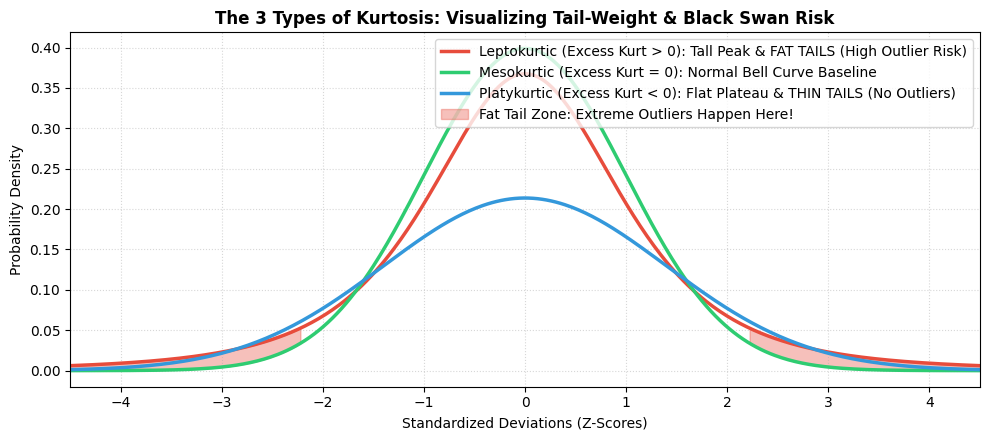

In [9]:
# 4. Kurtosis Geometry Visualization: Fat Tails vs. Thin Tails
x_vals = np.linspace(-4.5, 4.5, 400)

# 1. Leptokurtic: Student-t distribution (df=3 has heavy fat tails)
lepto_pdf = stats.t.pdf(x_vals, df=3)

# 2. Mesokurtic: Standard Normal Distribution N(0, 1)
meso_pdf = stats.norm.pdf(x_vals, 0, 1)

# 3. Platykurtic: Flatter curve (Normal with sigma=1.4, scaled)
platy_pdf = stats.norm.pdf(x_vals, 0, 1.4) * 0.75

plt.figure(figsize=(10, 4.5))
plt.plot(x_vals, lepto_pdf, color='#e74c3c', lw=2.5, label='Leptokurtic (Excess Kurt > 0): Tall Peak & FAT TAILS (High Outlier Risk)')
plt.plot(x_vals, meso_pdf,  color='#2ecc71', lw=2.5, label='Mesokurtic (Excess Kurt = 0): Normal Bell Curve Baseline')
plt.plot(x_vals, platy_pdf, color='#3498db', lw=2.5, label='Platykurtic (Excess Kurt < 0): Flat Plateau & THIN TAILS (No Outliers)')

# Highlight the Fat Tail region (where Leptokurtic curve stays higher than Normal!)
plt.fill_between(x_vals, lepto_pdf, meso_pdf, where=(x_vals > 2.2), color='#e74c3c', alpha=0.35, label='Fat Tail Zone: Extreme Outliers Happen Here!')
plt.fill_between(x_vals, lepto_pdf, meso_pdf, where=(x_vals < -2.2), color='#e74c3c', alpha=0.35)

plt.title('The 3 Types of Kurtosis: Visualizing Tail-Weight & Black Swan Risk', fontweight='bold', fontsize=12)
plt.xlabel('Standardized Deviations (Z-Scores)')
plt.ylabel('Probability Density')
plt.legend(loc='upper right', frameon=True)
plt.grid(True, linestyle=':', alpha=0.5)
plt.xlim(-4.5, 4.5)
plt.tight_layout()
plt.show()


--- 
## 5. Pearson's Median Skewness Coefficient (Robust Non-Parametric Skew)

* **What it does:** Calculates a quick, intuitive measure of skewness based on the distance between mean and median, scaled by standard deviation.
* **Mathematical Notation:**
  $$SK_p = \frac{3(\bar{x} - \tilde{x})}{s}$$
  $$\text{Pearson's Median Skewness} = \frac{3 \times (\text{Mean} - \text{Median})}{\text{Standard Deviation}}$$
  *Where:*
  * $SK_p$ (*Pearson's Skewness*): Non-parametric skewness index (typically ranges between -3 and +3)
  * $\bar{x}$ (*x-bar*): Sample mean
  * $\tilde{x}$ (*x-tilde*): Sample median
  * $s$ (*s*): Sample standard deviation
* **Naive Example:** Customer review wait times in minutes: `[2, 3, 3, 4, 20]` ($\bar{x} = 6.4, \tilde{x} = 3, s \approx 7.67$).
  $$SK_p = \frac{3(6.4 - 3)}{7.67} = \frac{10.2}{7.67} \approx +1.33$$
* **When to use:** Fast Exploratory Data Analysis (EDA) when 3rd moments are sensitive to extreme measurement noise.


Wait Times: [2, 3, 3, 4, 20]
Mean:   6.40 mins
Median: 3.00 mins
Standard Deviation: 7.64 mins
--------------------------------------------------
Pearson's Skewness (Python): +1.336
Pearson's Skewness (NumPy):  +1.336


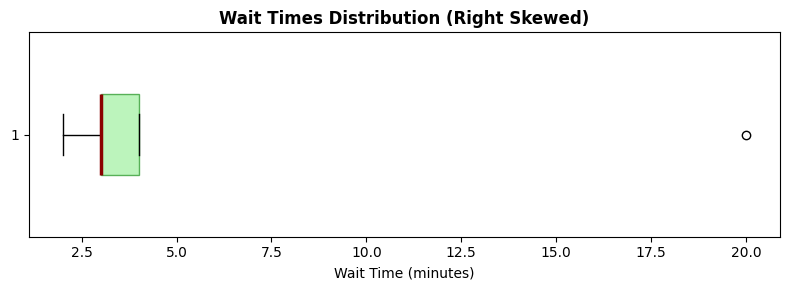

In [11]:
# 3. Pearson's Median Skewness Example
wait_times = [2, 3, 3, 4, 20]

# Plain Python / Standard Library
mean_val = statistics.mean(wait_times)
median_val = statistics.median(wait_times)
std_val = statistics.stdev(wait_times)
pearsons_skew_py = (3 * (mean_val - median_val)) / std_val

# NumPy Vector Operations
np_data = np.array(wait_times)
pearsons_skew_np = (3 * (np.mean(np_data) - np.median(np_data))) / np.std(np_data, ddof=1)

print(f"Wait Times: {wait_times}")
print(f"Mean:   {mean_val:.2f} mins")
print(f"Median: {median_val:.2f} mins")
print(f"Standard Deviation: {std_val:.2f} mins")
print("-" * 50)
print(f"Pearson's Skewness (Python): {pearsons_skew_py:+.3f}")
print(f"Pearson's Skewness (NumPy):  {pearsons_skew_np:+.3f}")

# Horizontal Boxplot Visualization
fig, ax = plt.subplots(figsize=(8, 3))
bp = ax.boxplot(wait_times, orientation='horizontal', patch_artist=True, widths=0.4,
                boxprops=dict(facecolor='lightgreen', color='green', alpha=0.6),
                medianprops=dict(color='darkred', linewidth=2.5))
ax.set_title("Wait Times Distribution (Right Skewed)", fontweight='bold')
ax.set_xlabel("Wait Time (minutes)")
plt.tight_layout()
plt.show()


### Sign & Result Interpretation for Skewness

| Skewness | Condition | Distribution | Tail Direction | Practical Meaning |
| :--- | :--- | :--- | :--- | :--- |
| **Positive ($> 0$)** | $\text{Mean} > \text{Median}$ | **Right-Skewed** | Long tail to the **Right** | High outliers drag the mean above the median |
| **Zero ($= 0$)** | $\text{Mean} = \text{Median}$ | **Symmetric** | Equal tails | Perfectly balanced around center |
| **Negative ($< 0$)** | $\text{Mean} < \text{Median}$ | **Left-Skewed** | Long tail to the **Left** | Low outliers drag the mean below the median |

---

### Result Interpretation for Wait Times (+1.336):
* **Sign (+):** Indicates **Right-skewed data** ($\text{Mean } 6.40 > \text{Median } 3.00$).
* **Magnitude (1.336):** Since $|1.336| > 1.0$, the distribution is **strongly skewed**.
* **Recommendation:** Use the **Median (3.00 mins)** rather than the Mean (6.40 mins) to describe typical customer experience.


---
## 6. Fixing Skewness: Data Transformations

* **Why fix skewness?**
  * Many machine learning models (Linear Regression, Logistic Regression, PCA) perform best when features are approximately normally distributed.
* **Common Remedies for Right-Skewed Data:**
  1. **Log Transformation:** $y = \log(x)$ or $y = \log(1 + x)$ (compresses large right-hand outliers).
  2. **Square Root Transformation:** $y = \sqrt{x}$ (mild right skew).
  3. **Box-Cox Power Transformation:** Finds the mathematically optimal power parameter $\lambda$.


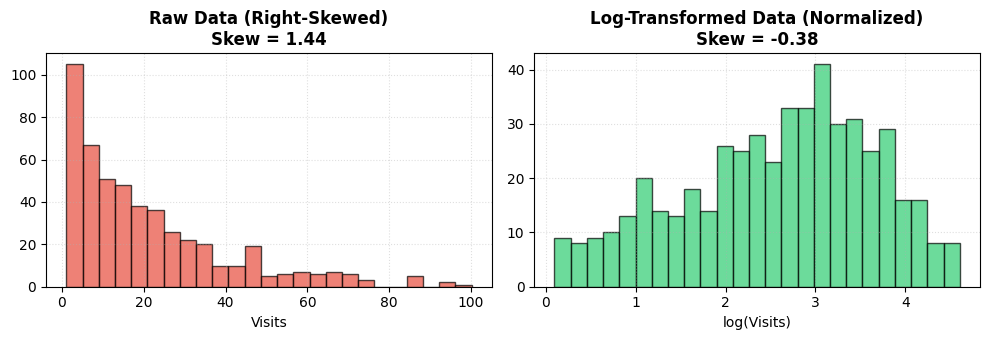

In [14]:
# 6. Fixing Right-Skewed Data using Log Transformation
# Heavily skewed positive values (e.g. Website page visits)
raw_visits = np.random.exponential(scale=20, size=500) + 1

# Log transform
log_visits = np.log(raw_visits)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))

# Raw Data
ax1.hist(raw_visits, bins=25, color='#e74c3c', alpha=0.7, edgecolor='black')
ax1.set_title(f'Raw Data (Right-Skewed)\nSkew = {stats.skew(raw_visits):.2f}', fontweight='bold')
ax1.set_xlabel('Visits')
ax1.grid(True, linestyle=':', alpha=0.4)

# Log Transformed
ax2.hist(log_visits, bins=25, color='#2ecc71', alpha=0.7, edgecolor='black')
ax2.set_title(f'Log-Transformed Data (Normalized)\nSkew = {stats.skew(log_visits):.2f}', fontweight='bold')
ax2.set_xlabel('log(Visits)')
ax2.grid(True, linestyle=':', alpha=0.4)

plt.tight_layout()
plt.show()


---
## 7. Master Cheat Sheet & Decision Matrix

| Metric | Range / Threshold | Interpretation | Shape Characteristic | Action / Decision |
| :--- | :--- | :--- | :--- | :--- |
| **Skewness** | $-0.5 \le \text{Skew} \le +0.5$ | **Fairly Symmetric** | Balanced left & right tails | Mean and Standard Deviation are safe to use. |
| **Skewness** | $+0.5 < \text{Skew} \le +1.0$ | **Moderately Right-Skewed** | Right tail pulled by high values | Prefer Median / IQR; consider square-root transform. |
| **Skewness** | $\text{Skew} > +1.0$ or $\text{Skew} < -1.0$ | **Highly Skewed** | Severe tail lopsidedness | Mean is distorted! Use Log or Box-Cox transform. |
| **Excess Kurtosis** | $\text{Excess Kurt} \approx 0$ | **Mesokurtic** | Normal Gaussian bell curve | Standard Normal assumptions hold cleanly. |
| **Excess Kurtosis** | $\mathbf{\text{Excess Kurt} > 0}$ | **Leptokurtic** | **Tall peak & FAT TAILS** | High risk of extreme outliers / Black Swans. Use robust metrics (Median, MAD, Modified Z). |
| **Excess Kurtosis** | $\mathbf{\text{Excess Kurt} < 0}$ | **Platykurtic** | **Flat top & THIN TAILS** | Very few outliers; safe, predictable bounds. |
